<a href="https://colab.research.google.com/github/carollinemelloo/ProcessamentoDeImagens/blob/main/Aula7Processamento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [9]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

In [2]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

In [3]:
num_epochs = 10
batch_size = 64
learning_rate = 0.01

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                         download=True, transform=transform)
test_set = torchvision.datasets.CIFAR10(root='./data', train=False,
                                        download=True, transform=transform)

train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                           shuffle=True)
test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size,
                                          shuffle=False)

100%|██████████| 170M/170M [20:54<00:00, 136kB/s]


In [4]:
class ConvNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3,6,5)
        self.pool = nn.MaxPool2d(2,2)
        self.conv2 = nn.Conv2d(6,16,5)
        self.fc1 = nn.Linear(16*5*5, 120)
        self.fc2 = nn.Linear(120,84)
        self.fc3 = nn.Linear(84,10)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = torch.flatten(x,1)
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        return self.fc3(x)

model = ConvNet().to(device)

In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(model.parameters(), lr=learning_rate, momentum=0.9)

for epoch in range(num_epochs):
  model.train()
  running_loss = 0.0
  for images, labels in train_loader:
    images, labels = images.to(device), labels.to(device)

    outputs = model(images)
    loss = criterion(outputs, labels)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    running_loss += loss.item()
  print(f'Epoch {epoch+1}: Loss = {running_loss / len(train_loader):.3f}')

Epoch 1: Loss = 1.816
Epoch 2: Loss = 1.391
Epoch 3: Loss = 1.232
Epoch 4: Loss = 1.123
Epoch 5: Loss = 1.051
Epoch 6: Loss = 0.989
Epoch 7: Loss = 0.940
Epoch 8: Loss = 0.890
Epoch 9: Loss = 0.858
Epoch 10: Loss = 0.821


In [7]:
classes = ('avião', 'carro', 'pássaro', 'gato', 'cervo',
           'cachorro', 'sapo', 'cavalo', 'navio', 'caminhâo')

model.eval()
correct, total = 0, 0
class_correct, class_total = [0] * 10, [0] * 10

with torch.no_grad():
  for images, labels in test_loader:
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    __, predicted = torch.max(outputs, 1)
    total += labels.size(0)
    correct += (predicted == labels).sum().item()
    for l, p in zip(labels.tolist(), predicted.tolist()):
      class_total[l] += 1
      class_correct[l] += int(l == p)

print(f"Acurácia geral: {100 * correct / total:.1f}%")
for i in range(10):
  print(f"{classes[i]:>9}: {100 * class_correct[i] / class_total[i]:.1f}%")

Acurácia geral: 63.3%
    avião: 72.5%
    carro: 68.8%
  pássaro: 49.5%
     gato: 49.5%
    cervo: 50.5%
 cachorro: 49.9%
     sapo: 86.0%
   cavalo: 63.1%
    navio: 71.3%
 caminhâo: 71.9%


Saving gato1.png to gato1 (1).png
Saving gato2.png to gato2 (1).png
Saving navio1.png to navio1 (1).png
Saving navio2.png to navio2 (1).png


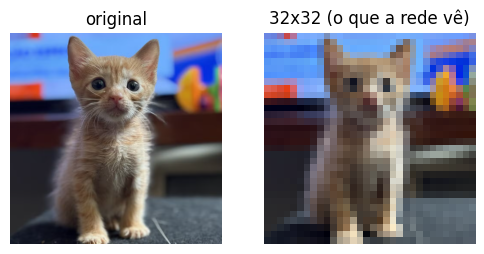

   cavalo: 54.2%
    cervo: 13.3%
    avião: 13.0%


In [10]:
from google.colab import files
from PIL import Image, ImageOps

uploaded = files.upload()
nome = list(uploaded.keys())[0]

img = Image.open(nome).convert('RGB')
img_32 = ImageOps.fit(img, (32, 32), method=Image.LANCZOS)

x = transform(img_32).unsqueeze(0).to(device)

model.eval()
with torch.no_grad():
    probs = F.softmax(model(x), dim=1)[0]

fig, axes = plt.subplots(1, 2, figsize=(6, 3))
axes[0].imshow(img);    axes[0].set_title('original');        axes[0].axis('off')
axes[1].imshow(img_32); axes[1].set_title('32x32 (o que a rede vê)'); axes[1].axis('off')
plt.show()

top = torch.topk(probs, 3)
for p, i in zip(top.values, top.indices):
    print(f'{classes[i]:>9}: {100 * p:.1f}%')